*Data Science and Visualisation 24ADI204*

---

# **Week 6:** Feature Engineering
**Team 16**

**Importing Dataset:**

---



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
file_path = '/content/drive/MyDrive/Chicago_Crimes_2001_to_Present.csv'
import os

print(os.path.exists(file_path))

True


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv(file_path, low_memory=False)

print("Dataset shape:", df.shape)
print(df.head())


Dataset shape: (8422096, 22)
         ID Case Number                    Date                    Block  \
0  13311263    JG503434  07/29/2022 03:39:00 AM          023XX S TROY ST   
1  13053066    JG103252  01/03/2023 04:44:00 PM  039XX W WASHINGTON BLVD   
2  12131221    JD327000  08/10/2020 09:45:00 AM        015XX N DAMEN AVE   
3  11227634    JB147599  08/26/2017 10:00:00 AM      001XX W RANDOLPH ST   
4  13203321    JG415333  09/06/2023 05:00:00 PM         002XX N Wells st   

   IUCR                Primary Type                     Description  \
0  1582  OFFENSE INVOLVING CHILDREN               CHILD PORNOGRAPHY   
1  2017                   NARCOTICS   MANUFACTURE / DELIVER - CRACK   
2  0326                     ROBBERY  AGGRAVATED VEHICULAR HIJACKING   
3  0281         CRIM SEXUAL ASSAULT                  NON-AGGRAVATED   
4  1320             CRIMINAL DAMAGE                      TO VEHICLE   

                     Location Description  Arrest  Domestic  ...  Ward  \
0            

In [ ]:
import pandas as pd
import numpy as np

df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

df['Hour'] = df['Date'].dt.hour
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day

**1.Data scaling and normalization**

---


 Scaling makes numerical features comparable in magnitude. We'll demonstrate Min-Max Scaling, Z-score Standardization, Robust Scaling, and Max-Abs Scaling on the coordinate columns. These are syllabus demonstrations; retain original coordinates for mapping.

**A. Min-Max Scaling**

---


Purpose: Converts numerical values to a range of 0 to 1, making their scales comparable.
What it does: Scales Hour, Month, and Day to the range 0–1

In [ ]:
from sklearn.preprocessing import MinMaxScaler

cols_minmax = ['Hour', 'Month', 'Day']
valid_minmax = df[cols_minmax].notna().all(axis=1)

scaler_minmax = MinMaxScaler()

df.loc[valid_minmax, ['Hour_MinMax', 'Month_MinMax', 'Day_MinMax']] = (
    scaler_minmax.fit_transform(df.loc[valid_minmax, cols_minmax])
)

print(df[['Hour_MinMax', 'Month_MinMax', 'Day_MinMax']].head())

   Hour_MinMax  Month_MinMax  Day_MinMax
0     0.130435      0.545455    0.933333
1     0.695652      0.000000    0.066667
2     0.391304      0.636364    0.300000
3     0.434783      0.636364    0.833333
4     0.739130      0.727273    0.166667


**B. Z-score Standardization**

---


What it does: Standardizes X Coordinate and Y Coordinate to have approximately zero mean and unit standard deviation.

In [ ]:
from sklearn.preprocessing import StandardScaler

cols_coords = ['X Coordinate', 'Y Coordinate']
valid_coords = df[cols_coords].notna().all(axis=1)

scaler_z = StandardScaler()

df.loc[valid_coords, ['X_ZScore', 'Y_ZScore']] = (
    scaler_z.fit_transform(df.loc[valid_coords, cols_coords])
)

print(df[['X_ZScore', 'Y_ZScore']].head())

   X_ZScore  Y_ZScore
0       NaN       NaN
1       NaN       NaN
2 -0.109800  0.739654
3       NaN       NaN
4  0.592105  0.490852


**C. Robust Scaling**

---


What it does: Scales coordinates using the median and interquartile range, reducing sensitivity to extreme values.

In [ ]:
from sklearn.preprocessing import RobustScaler

scaler_robust = RobustScaler()

df.loc[valid_coords, ['X_Robust', 'Y_Robust']] = (
    scaler_robust.fit_transform(df.loc[valid_coords, cols_coords])
)

print(df[['X_Robust', 'Y_Robust']].head())

   X_Robust  Y_Robust
0       NaN       NaN
1       NaN       NaN
2 -0.146348  0.376066
3       NaN       NaN
4  0.363726  0.215316


**2. Categorical Encoding**

---



**A. Label Encoding**

---



Purpose: Assigns a numerical code to each categorical value.
What the code does: Converts each unique crime category in Primary Type into an integer and stores it in PrimaryType_Code, without replacing the original column.

In [ ]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

df['PrimaryType_Code'] = encoder.fit_transform(
    df['Primary Type'].fillna('Unknown').astype(str)
)

print(df[['Primary Type', 'PrimaryType_Code']].head())

                 Primary Type  PrimaryType_Code
0  OFFENSE INVOLVING CHILDREN                22
1                   NARCOTICS                19
2                     ROBBERY                29
3         CRIM SEXUAL ASSAULT                 5
4             CRIMINAL DAMAGE                 6


**B. One-Hot Encoding**

---


Purpose: Represents categories as separate binary indicator columns containing 0s and 1s.
What the code does: Creates separate indicator columns for the values of Arrest and Domestic, including indicators for missing values.

In [ ]:
encoded_flags = pd.get_dummies(
    df[['Arrest', 'Domestic']],
    columns=['Arrest', 'Domestic'],
    dummy_na=True,
    dtype=int
)

print(encoded_flags.head())

   Arrest_False  Arrest_True  Arrest_nan  Domestic_False  Domestic_True  \
0             0            1           0               1              0   
1             0            1           0               1              0   
2             0            1           0               1              0   
3             1            0           0               1              0   
4             1            0           0               1              0   

   Domestic_nan  
0             0  
1             0  
2             0  
3             0  
4             0  


**C. One-Hot Encoding for Crime Types**

---


Purpose: Represents nominal crime categories separately without assigning them an artificial order.
What the code does: Selects the ten most frequent crime categories and creates one binary column for each category in a demonstration subset.

In [ ]:
top_crimes = df['Primary Type'].value_counts().head(10).index

sample = df[df['Primary Type'].isin(top_crimes)]

crime_onehot = pd.get_dummies(
    sample['Primary Type'],
    prefix='Crime',
    dtype=int
)

print(crime_onehot.head())

**Binning and Discretization**

---



**A. Time-Period Binning**

---


Purpose: Groups numerical hours into meaningful time categories for easier analysis.
What the code does: Extracts the hour from Date, divides the day into five time periods, and creates a new TimePeriod column.

In [ ]:
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df['Hour'] = df['Date'].dt.hour

df['TimePeriod'] = pd.cut(
    df['Hour'],
    bins=[-1, 5, 11, 16, 20, 23],
    labels=[
        'Night', 'Morning', 'Afternoon',
        'Evening', 'Late Night'
    ]
)

print(df[['Hour', 'TimePeriod']].head())
print(df['TimePeriod'].value_counts().sort_index())

   Hour TimePeriod
0     3      Night
1    16  Afternoon
2     9    Morning
3    10    Morning
4    17    Evening
TimePeriod
Night         1430630
Morning       1709417
Afternoon     2179366
Evening       1832615
Late Night    1270068
Name: count, dtype: int64


**B. Year Binning**

---



Purpose: Groups individual years into five-year intervals to





simplify long-term trend analysis.
What the code does: Converts Year to a numeric type and assigns each year to a predefined five-year category.

In [ ]:
df['Year'] = pd.to_numeric(df['Year'], errors='coerce')

df['YearGroup'] = pd.cut(
    df['Year'],
    bins=[2000, 2005, 2010, 2015, 2020, 2025, 2030],
    labels=[
        '2001-2005', '2006-2010', '2011-2015',
        '2016-2020', '2021-2025', '2026-2030'
    ],
    include_lowest=True
)

print(df[['Year', 'YearGroup']].head())

   Year  YearGroup
0  2022  2021-2025
1  2023  2021-2025
2  2020  2016-2020
3  2017  2016-2020
4  2023  2021-2025


**4. Skewness Analysis and Log Transformation**

---




**A. Skewness Analysis**

---


Purpose: Measures how asymmetric a numerical distribution is.
What the code does: Counts incidents for each Primary Type and calculates the skewness of those category counts.

In [ ]:
crime_counts = df['Primary Type'].value_counts()

print("Skewness:", crime_counts.skew())
print(crime_counts.head(10))

Skewness: 2.3566810075806837
Primary Type
THEFT                  1787724
BATTERY                1534656
CRIMINAL DAMAGE         957771
NARCOTICS               763699
ASSAULT                 564237
OTHER OFFENSE           525120
BURGLARY                445335
MOTOR VEHICLE THEFT     430562
DECEPTIVE PRACTICE      387815
ROBBERY                 314530
Name: count, dtype: int64


**B. Log Transformation**

---


Purpose: Compresses large values to make differences in highly uneven distributions easier to inspect.
What the code does: Creates a frequency table of crime categories and applies log1p() to the incident counts, storing the transformed values in Log_Count.

In [ ]:
import numpy as np

crime_frequency = crime_counts.rename_axis(
    'Primary Type'
).reset_index(name='Incident Count')

crime_frequency['Log_Count'] = np.log1p(
    crime_frequency['Incident Count']
)

print(crime_frequency.head())

      Primary Type  Incident Count  Log_Count
0            THEFT         1787724  14.396454
1          BATTERY         1534656  14.243817
2  CRIMINAL DAMAGE          957771  13.772365
3        NARCOTICS          763699  13.545930
4          ASSAULT          564237  13.243231


**C. Compare Before and After Transformation**

---


Purpose: Visually compares the original count distribution with the log-transformed distribution.
What the code does: Draws two histograms side by side to show how the log transformation changes the distribution.

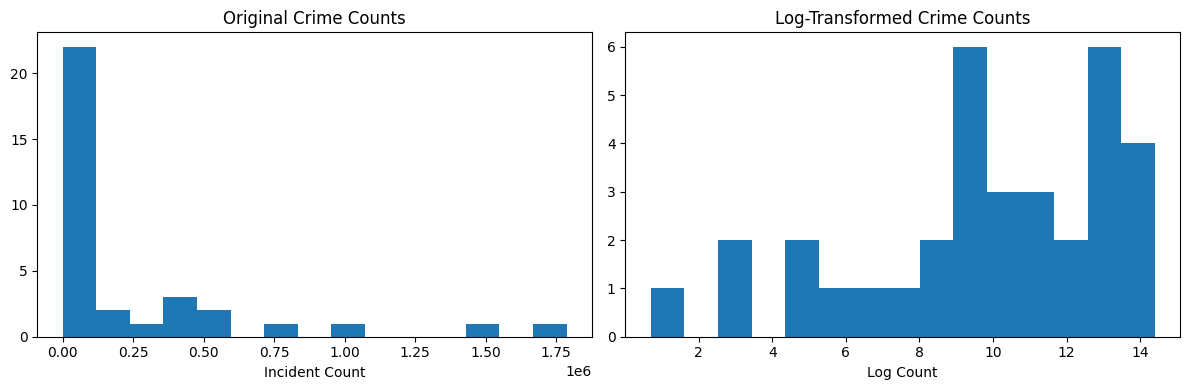

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(crime_frequency['Incident Count'], bins=15)
axes[0].set_title('Original Crime Counts')
axes[0].set_xlabel('Incident Count')

axes[1].hist(crime_frequency['Log_Count'], bins=15)
axes[1].set_title('Log-Transformed Crime Counts')
axes[1].set_xlabel('Log Count')

plt.tight_layout()
plt.show()

**Processed Data**

---



In [ ]:
output_path = '/content/chicago_crime_week6_scaled.csv'

df.to_csv(output_path, index=False)

print("Saved successfully:", output_path)

from google.colab import files
files.download(output_path)

Saved successfully: /content/chicago_crime_week6_scaled.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>